# Pearson correlation: tweet volume vs returns

Original file name: `Correlation Analysis 2.ipynb`

**Runs from the data committed in this repository** (`data/derived/`, `data/prices/`, `data/tweet_counts/`, `data/annotation/`). Environment: see `requirements.txt` (Python 3.11, pandas 1.5.3).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [2]:
# Load the datasets
btc_data = pd.read_csv('../data/prices/BTC-USD_1d_2021.csv')
eth_data = pd.read_csv('../data/prices/ETH-USD_1d_2021.csv')
tweet_data = pd.read_excel('../data/tweet_counts/daily_tweet_counts_2021.xlsx')

# Explore the first few rows
btc_data.head(), eth_data.head(), tweet_data.head()

(         Date          Open          High           Low         Close  \
 0  2021-01-01  28994.009766  29600.626953  28803.585938  29374.152344   
 1  2021-01-02  29376.455078  33155.117188  29091.181641  32127.267578   
 2  2021-01-03  32129.408203  34608.558594  32052.316406  32782.023438   
 3  2021-01-04  32810.949219  33440.218750  28722.755859  31971.914062   
 4  2021-01-05  31977.041016  34437.589844  30221.187500  33992.429688   
 
         Volume  Dividends  Stock Splits   Returns  
 0  40730301359          0             0       NaN  
 1  67865420765          0             0  0.093726  
 2  78665235202          0             0  0.020380  
 3  81163475344          0             0 -0.024712  
 4  67547324782          0             0  0.063197  ,
          Date         Open         High         Low        Close       Volume  \
 0  2021-01-01   737.708374   749.201843  719.792236   730.367554  13652004358   
 1  2021-01-02   730.402649   786.798462  718.109497   774.534973  1974

In [3]:
btc_data['Returns'] = btc_data['Close'].pct_change()
eth_data['Returns'] = eth_data['Close'].pct_change()

btc_data.dropna(subset=['Returns'], inplace=True)
eth_data.dropna(subset=['Returns'], inplace=True)


# Aggregation

In [4]:
# Ensure 'Date' columns are in datetime format for all dataframes
btc_data['Date'] = pd.to_datetime(btc_data['Date'])
eth_data['Date'] = pd.to_datetime(eth_data['Date'])
tweet_data['Date'] = pd.to_datetime(tweet_data['Date'])

# Daily aggregation
daily_data = pd.merge(btc_data[['Date', 'Returns']], eth_data[['Date', 'Returns']], on='Date', suffixes=('_btc', '_eth'))
daily_data = pd.merge(daily_data, tweet_data, on='Date')

# Weekly aggregation
weekly_data = daily_data.resample('W-Fri', on='Date').mean().reset_index()

# Monthly aggregation
monthly_data = daily_data.resample('M', on='Date').mean().reset_index()


# Pearson's Correlation Coefficient and p-value Correlation Analysis

In [5]:
def compute_correlation(data, col1, col2):
    return pearsonr(data[col1], data[col2])

correlation_results = {
    "Frequency": ["Daily", "Weekly", "Monthly"],
    "BTC_Returns_Tweet_Corr": [],
    "BTC_Returns_Tweet_P_Value": [],
    "ETH_Returns_Tweet_Corr": [],
    "ETH_Returns_Tweet_P_Value": []
}

datasets = [daily_data, weekly_data, monthly_data]
for data in datasets:
    btc_corr, btc_p_value = compute_correlation(data, 'Returns_btc', 'Count')
    eth_corr, eth_p_value = compute_correlation(data, 'Returns_eth', 'Count')
    
    correlation_results["BTC_Returns_Tweet_Corr"].append(btc_corr)
    correlation_results["BTC_Returns_Tweet_P_Value"].append(btc_p_value)
    correlation_results["ETH_Returns_Tweet_Corr"].append(eth_corr)
    correlation_results["ETH_Returns_Tweet_P_Value"].append(eth_p_value)

correlation_df = pd.DataFrame(correlation_results)
correlation_df

,Frequency,BTC_Returns_Tweet_Corr,BTC_Returns_Tweet_P_Value,ETH_Returns_Tweet_Corr,ETH_Returns_Tweet_P_Value
0,Daily,-0.065406,0.213165,-0.122729,0.019164
1,Weekly,-0.238071,0.089214,-0.319792,0.020830
2,Monthly,-0.424781,0.168683,-0.621914,0.030837


# Scatter Plot

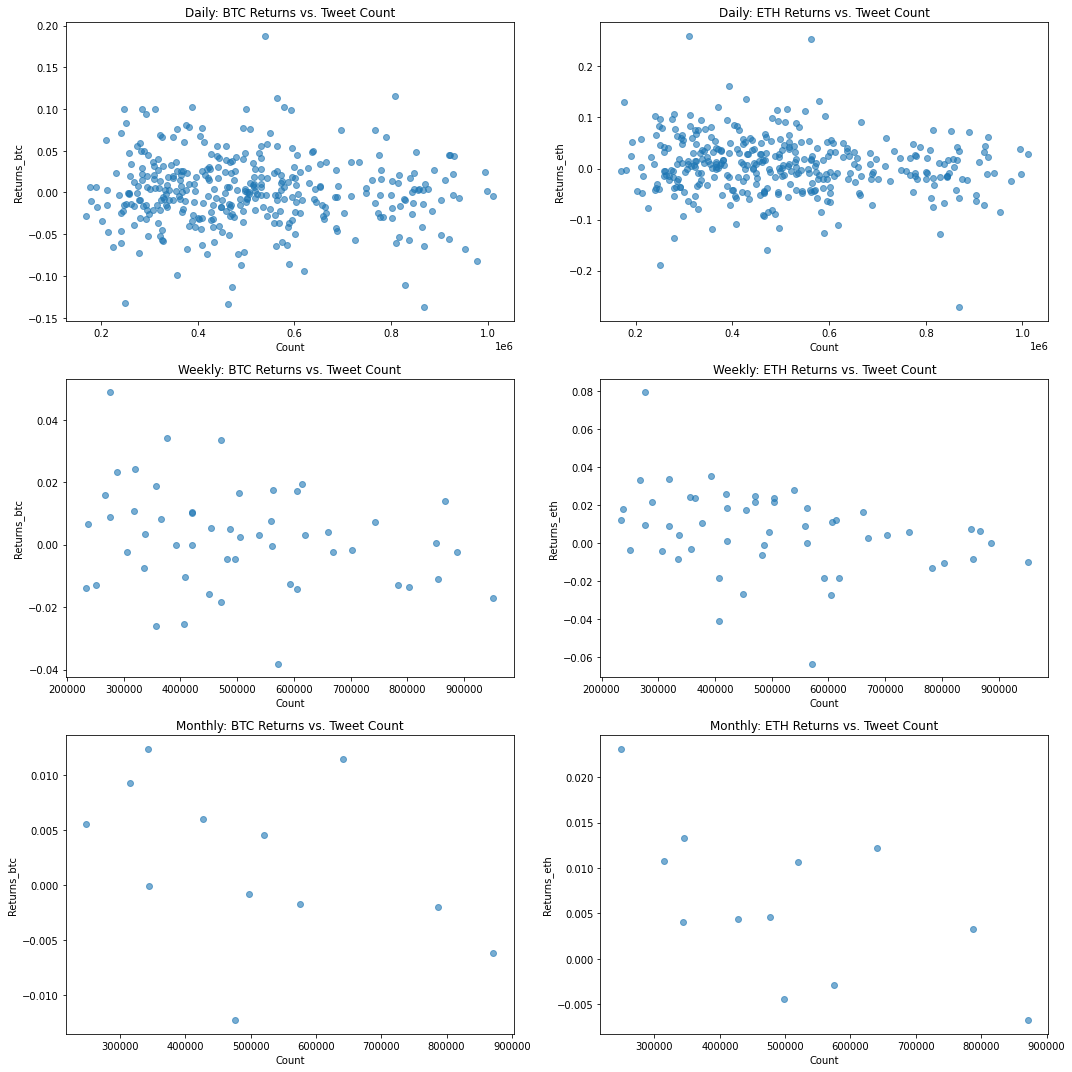

In [6]:
def plot_scatter(data, x_col, y_col, title, ax):
    ax.scatter(data[x_col], data[y_col], alpha=0.6)
    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 15))

plot_scatter(daily_data, 'Count', 'Returns_btc', 'Daily: BTC Returns vs. Tweet Count', axes[0, 0])
plot_scatter(daily_data, 'Count', 'Returns_eth', 'Daily: ETH Returns vs. Tweet Count', axes[0, 1])
plot_scatter(weekly_data, 'Count', 'Returns_btc', 'Weekly: BTC Returns vs. Tweet Count', axes[1, 0])
plot_scatter(weekly_data, 'Count', 'Returns_eth', 'Weekly: ETH Returns vs. Tweet Count', axes[1, 1])
plot_scatter(monthly_data, 'Count', 'Returns_btc', 'Monthly: BTC Returns vs. Tweet Count', axes[2, 0])
plot_scatter(monthly_data, 'Count', 'Returns_eth', 'Monthly: ETH Returns vs. Tweet Count', axes[2, 1])

plt.tight_layout()
plt.show()